# DRIVE V6 — End-to-End Hybrid TransUNet + Feature-GNN

**Main change:** the old post-processing GNN is removed. The GNN now operates on learned bottleneck feature nodes and is trained end-to-end with the CNN, Transformer, decoder, and segmentation loss.

Architecture: **CNN encoder → parallel Transformer + feature-GNN → gated fusion → attention decoder → vessel mask**.

This version also adds multi-scale edge-aware feature enhancement and keeps deep supervision. It is designed to improve thin-vessel overlap/Dice, but the exact Dice improvement must be measured after training.


## 1. Upload and extract DRIVE

In [1]:
from google.colab import files
import os, zipfile, glob, shutil

print("Upload the DRIVE datasets.zip file")
uploaded = files.upload()
assert uploaded, "No file uploaded."

archive = next(iter(uploaded.keys()))
os.makedirs("drive_data_raw", exist_ok=True)
os.makedirs("drive_data", exist_ok=True)

with zipfile.ZipFile(archive, "r") as z:
    z.extractall("drive_data_raw")

# The supplied DRIVE archive contains nested training.zip and test.zip.
for nested in ["training.zip", "test.zip"]:
    path = os.path.join("drive_data_raw", nested)
    if os.path.exists(path):
        with zipfile.ZipFile(path, "r") as z:
            z.extractall("drive_data")

train_images = glob.glob("drive_data/training/images/*.tif")
train_masks = glob.glob("drive_data/training/1st_manual/*.gif")

assert len(train_images) == 20, f"Expected 20 DRIVE training images, found {len(train_images)}"
assert len(train_masks) == 20, f"Expected 20 DRIVE masks, found {len(train_masks)}"

print("DRIVE training images:", len(train_images))
print("DRIVE training masks :", len(train_masks))


Upload the DRIVE datasets.zip file


Saving datasets.zip to datasets.zip
DRIVE training images: 20
DRIVE training masks : 20


## 2. Install dependencies

In [2]:
!pip install -q pillow numpy torch torchvision scikit-image scikit-learn scipy matplotlib opencv-python-headless pandas

## 3. Imports, preprocessing, augmentation and datasets

In [3]:
import os, glob, random, math, csv
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
from PIL import Image

from skimage.morphology import skeletonize, dilation, disk
from skimage.metrics import structural_similarity
from scipy.ndimage import distance_transform_edt

from sklearn.metrics import (
    roc_auc_score, roc_curve,
    average_precision_score, precision_recall_curve,
    confusion_matrix
)

import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def enhance_retina_rgb(img_pil):
    arr = np.array(img_pil.convert("RGB"))
    g = arr[:, :, 1]
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    g2 = clahe.apply(g)

    out = arr.astype(np.float32)
    out[:, :, 1] = 0.35 * out[:, :, 1] + 0.65 * g2
    out[:, :, 0] = 0.80 * out[:, :, 0] + 0.20 * g2
    out[:, :, 2] = 0.80 * out[:, :, 2] + 0.20 * g2

    return Image.fromarray(np.clip(out, 0, 255).astype(np.uint8))

def paired_augment(img, mask):
    if torch.rand(1).item() < 0.5:
        img, mask = TF.hflip(img), TF.hflip(mask)
    if torch.rand(1).item() < 0.5:
        img, mask = TF.vflip(img), TF.vflip(mask)

    angle = float(torch.empty(1).uniform_(-30, 30))
    scale = float(torch.empty(1).uniform_(0.90, 1.10))
    shear = [float(torch.empty(1).uniform_(-8, 8)), 0.0]

    img = TF.affine(
        img, angle=angle, translate=[0,0], scale=scale, shear=shear,
        interpolation=InterpolationMode.BILINEAR
    )
    mask = TF.affine(
        mask, angle=angle, translate=[0,0], scale=scale, shear=shear,
        interpolation=InterpolationMode.NEAREST
    )

    if torch.rand(1).item() < 0.7:
        img = TF.adjust_brightness(img, float(torch.empty(1).uniform_(0.80, 1.20)))
        img = TF.adjust_contrast(img, float(torch.empty(1).uniform_(0.80, 1.25)))

    if torch.rand(1).item() < 0.5:
        img = TF.adjust_gamma(img.clamp(0,1), float(torch.empty(1).uniform_(0.75, 1.35)))

    return img, (mask > 0.5).float()

class RetinaDataset(Dataset):
    def __init__(self, root_dir, split="training", image_size=(512,512), augment=False):
        self.image_size = image_size
        self.augment = augment
        self.images = sorted(glob.glob(os.path.join(root_dir, split, "images", "*.tif")))
        self.masks = sorted(glob.glob(os.path.join(root_dir, split, "1st_manual", "*.gif")))
        assert len(self.images) == len(self.masks) > 0

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = Image.open(self.images[idx]).convert("RGB").resize(self.image_size, Image.BILINEAR)
        mask = Image.open(self.masks[idx]).convert("L").resize(self.image_size, Image.NEAREST)

        img = enhance_retina_rgb(img)
        img_t = TF.to_tensor(img)
        mask_t = torch.from_numpy((np.array(mask) > 127).astype(np.float32)).unsqueeze(0)

        if self.augment:
            img_t, mask_t = paired_augment(img_t, mask_t)

        img_t = TF.normalize(img_t, mean=[0.5]*3, std=[0.5]*3)
        return img_t, mask_t

class ThinVesselPatchDataset(Dataset):
    def __init__(
        self, base_subset, patch_size=256, patches_per_image=32,
        min_vessel_fraction=0.006, max_vessel_fraction=0.12
    ):
        self.base = base_subset
        self.patch = patch_size
        self.ppi = patches_per_image
        self.min_v = min_vessel_fraction
        self.max_v = max_vessel_fraction

    def __len__(self):
        return len(self.base) * self.ppi

    def __getitem__(self, idx):
        img, mask = self.base[idx // self.ppi]
        _, H, W = img.shape
        p = self.patch
        best = None

        for _ in range(24):
            top = random.randint(0, max(0, H-p))
            left = random.randint(0, max(0, W-p))
            x = img[:, top:top+p, left:left+p]
            y = mask[:, top:top+p, left:left+p]
            frac = float(y.mean())
            best = (x, y)
            if self.min_v <= frac <= self.max_v:
                return x, y

        return best


Device: cuda


## 4. V6 architecture — CNN + Transformer + end-to-end feature-GNN

Unlike V5, the graph branch is **inside the segmentation network**. Each bottleneck spatial location is treated as a graph node and exchanges messages with its 8 neighboring nodes. The graph branch and Transformer branch are fused before decoding.


In [4]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.GELU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.GELU()
        )
    def forward(self, x):
        return self.block(x)


class MultiScaleEdgeAttention(nn.Module):
    """Preserves fine vessels using multi-scale dilated context + learned edge attention."""
    def __init__(self, ch):
        super().__init__()
        mid = max(ch // 4, 16)
        self.d1 = nn.Conv2d(ch, mid, 3, padding=1, dilation=1, bias=False)
        self.d2 = nn.Conv2d(ch, mid, 3, padding=2, dilation=2, bias=False)
        self.d3 = nn.Conv2d(ch, mid, 3, padding=3, dilation=3, bias=False)
        self.mix = nn.Sequential(
            nn.Conv2d(mid * 3, ch, 1, bias=False),
            nn.BatchNorm2d(ch), nn.GELU()
        )
        self.edge_gate = nn.Sequential(
            nn.Conv2d(ch, max(ch // 8, 8), 3, padding=1, bias=False),
            nn.GELU(),
            nn.Conv2d(max(ch // 8, 8), 1, 1),
            nn.Sigmoid()
        )
        self.out = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(ch), nn.GELU()
        )

    def forward(self, x):
        z = torch.cat([self.d1(x), self.d2(x), self.d3(x)], dim=1)
        z = self.mix(z)
        gate = self.edge_gate(z)
        return self.out(x + z * gate)


class TransformerBottleneck(nn.Module):
    def __init__(self, in_ch=512, embed_dim=384, depth=4, heads=6, base_hw=16):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, embed_dim, 1)
        self.pos2d = nn.Parameter(torch.zeros(1, embed_dim, base_hw, base_hw))
        nn.init.trunc_normal_(self.pos2d, std=0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=heads,
            dim_feedforward=embed_dim * 4,
            dropout=0.10, activation="gelu",
            batch_first=True, norm_first=True
        )
        self.enc = nn.TransformerEncoder(layer, num_layers=depth)
        self.out = nn.Conv2d(embed_dim, in_ch, 1)

    def forward(self, x):
        z = self.proj(x)
        B, C, H, W = z.shape
        pos = F.interpolate(self.pos2d, size=(H, W), mode="bilinear", align_corners=False)
        z = (z + pos).flatten(2).transpose(1, 2)
        z = self.enc(z).transpose(1, 2).reshape(B, C, H, W)
        return self.out(z)


class GridGraphLayer(nn.Module):
    """
    End-to-end graph message passing on the bottleneck feature grid.
    Each HxW feature location is a node; its 8 surrounding locations are neighbors.
    """
    def __init__(self, ch, dropout=0.10):
        super().__init__()
        self.self_proj = nn.Conv2d(ch, ch, 1, bias=False)
        self.neigh_proj = nn.Conv2d(ch, ch, 1, bias=False)
        self.norm = nn.BatchNorm2d(ch)
        self.drop = nn.Dropout2d(dropout)

    def forward(self, x):
        # 3x3 neighborhood = fixed spatial graph; remove the center to get neighbor messages.
        summed_3x3 = F.avg_pool2d(x, kernel_size=3, stride=1, padding=1) * 9.0
        neigh = (summed_3x3 - x) / 8.0
        z = self.self_proj(x) + self.neigh_proj(neigh)
        z = self.drop(F.gelu(self.norm(z)))
        return x + z


class FeatureGNN(nn.Module):
    def __init__(self, ch=512, depth=4):
        super().__init__()
        self.layers = nn.ModuleList([GridGraphLayer(ch) for _ in range(depth)])
        self.out = nn.Sequential(
            nn.Conv2d(ch, ch, 1, bias=False),
            nn.BatchNorm2d(ch), nn.GELU()
        )

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return self.out(x)


class BranchFusion(nn.Module):
    """Learns how much Transformer and GNN information to use at each spatial location."""
    def __init__(self, ch):
        super().__init__()
        self.gate = nn.Sequential(
            nn.Conv2d(ch * 2, ch, 1, bias=False),
            nn.BatchNorm2d(ch), nn.GELU(),
            nn.Conv2d(ch, 2, 1)
        )
        self.refine = DoubleConv(ch, ch)

    def forward(self, t, g):
        w = torch.softmax(self.gate(torch.cat([t, g], dim=1)), dim=1)
        z = w[:, 0:1] * t + w[:, 1:2] * g
        return self.refine(z)


class AttentionGate(nn.Module):
    def __init__(self, skip_ch, gate_ch, inter_ch):
        super().__init__()
        self.skip = nn.Conv2d(skip_ch, inter_ch, 1, bias=False)
        self.gate = nn.Conv2d(gate_ch, inter_ch, 1, bias=False)
        self.psi = nn.Sequential(
            nn.GELU(),
            nn.Conv2d(inter_ch, 1, 1),
            nn.Sigmoid()
        )

    def forward(self, skip, gate):
        a = self.psi(self.skip(skip) + self.gate(gate))
        return skip * a


class HybridTransUNetGNNV6(nn.Module):
    def __init__(self):
        super().__init__()

        # CNN encoder
        self.e1 = DoubleConv(3, 32)
        self.edge1 = MultiScaleEdgeAttention(32)
        self.e2 = DoubleConv(32, 64)
        self.edge2 = MultiScaleEdgeAttention(64)
        self.e3 = DoubleConv(64, 128)
        self.e4 = DoubleConv(128, 256)
        self.pool = nn.MaxPool2d(2)

        self.bridge = DoubleConv(256, 512)

        # Parallel global + structural reasoning
        self.trans = TransformerBottleneck(512, 384, depth=4, heads=6, base_hw=16)
        self.gnn = FeatureGNN(512, depth=4)
        self.fusion = BranchFusion(512)

        # Attention decoder
        self.u4 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.a4 = AttentionGate(256, 256, 128)
        self.d4 = DoubleConv(512, 256)

        self.u3 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.a3 = AttentionGate(128, 128, 64)
        self.d3 = DoubleConv(256, 128)

        self.u2 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.a2 = AttentionGate(64, 64, 32)
        self.d2 = DoubleConv(128, 64)

        self.u1 = nn.ConvTranspose2d(64, 32, 2, 2)
        self.a1 = AttentionGate(32, 32, 16)
        self.d1 = DoubleConv(64, 32)

        self.out = nn.Conv2d(32, 1, 1)
        self.aux2 = nn.Conv2d(64, 1, 1)
        self.aux3 = nn.Conv2d(128, 1, 1)

    def forward(self, x):
        e1 = self.edge1(self.e1(x))
        e2 = self.edge2(self.e2(self.pool(e1)))
        e3 = self.e3(self.pool(e2))
        e4 = self.e4(self.pool(e3))

        b = self.bridge(self.pool(e4))

        # Both branches see the SAME learned CNN features.
        t = self.trans(b)
        g = self.gnn(b)
        b = self.fusion(t, g)

        u4 = self.u4(b)
        d4 = self.d4(torch.cat([u4, self.a4(e4, u4)], dim=1))

        u3 = self.u3(d4)
        d3 = self.d3(torch.cat([u3, self.a3(e3, u3)], dim=1))

        u2 = self.u2(d3)
        d2 = self.d2(torch.cat([u2, self.a2(e2, u2)], dim=1))

        u1 = self.u1(d2)
        d1 = self.d1(torch.cat([u1, self.a1(e1, u1)], dim=1))

        main = self.out(d1)

        if self.training:
            aux2 = F.interpolate(self.aux2(d2), size=main.shape[-2:], mode="bilinear", align_corners=False)
            aux3 = F.interpolate(self.aux3(d3), size=main.shape[-2:], mode="bilinear", align_corners=False)
            return main, aux2, aux3

        return main


## 5. Losses and metrics

In [5]:
def soft_dice_loss(logits, y, eps=1e-6):
    p = torch.sigmoid(logits)
    dims = (0,2,3)
    inter = (p*y).sum(dims)
    den = p.sum(dims) + y.sum(dims)
    return (1 - (2*inter+eps)/(den+eps)).mean()

def focal_tversky_loss(logits, y, alpha=0.55, beta=0.45, gamma=0.75, eps=1e-6):
    p = torch.sigmoid(logits)
    dims = (0,2,3)
    tp = (p*y).sum(dims)
    fp = (p*(1-y)).sum(dims)
    fn = ((1-p)*y).sum(dims)
    tv = (tp+eps)/(tp + alpha*fp + beta*fn + eps)
    return ((1-tv)**gamma).mean()

def soft_erode(img):
    p1 = -F.max_pool2d(-img, (3,1), (1,1), (1,0))
    p2 = -F.max_pool2d(-img, (1,3), (1,1), (0,1))
    return torch.minimum(p1, p2)

def soft_dilate(img):
    return F.max_pool2d(img, (3,3), (1,1), (1,1))

def soft_open(img):
    return soft_dilate(soft_erode(img))

def soft_skel(img, iters=10):
    img1 = soft_open(img)
    skel = F.relu(img-img1)
    for _ in range(iters):
        img = soft_erode(img)
        img1 = soft_open(img)
        delta = F.relu(img-img1)
        skel = skel + F.relu(delta-skel*delta)
    return skel

def soft_cldice_loss(logits, y, eps=1e-6):
    p = torch.sigmoid(logits)
    sp = soft_skel(p, 10)
    sy = soft_skel(y, 10)

    tprec = (sp*y).sum((1,2,3))/(sp.sum((1,2,3))+eps)
    tsens = (sy*p).sum((1,2,3))/(sy.sum((1,2,3))+eps)
    cl = (2*tprec*tsens+eps)/(tprec+tsens+eps)
    return (1-cl).mean()

class V6Loss(nn.Module):
    def forward_one(self, logits, y):
        return (
            0.30*focal_tversky_loss(logits,y) +
            0.50*soft_dice_loss(logits,y) +
            0.20*soft_cldice_loss(logits,y)
        )

    def forward(self, outputs, y):
        if isinstance(outputs, (tuple,list)):
            main, a2, a3 = outputs
            return (
                self.forward_one(main,y) +
                0.25*self.forward_one(a2,y) +
                0.15*self.forward_one(a3,y)
            )
        return self.forward_one(outputs,y)

def binary_metrics(probs, targets, threshold):
    pred = (probs >= threshold).astype(np.uint8)
    gt = (targets > 0.5).astype(np.uint8)

    tp = np.logical_and(pred==1, gt==1).sum()
    fp = np.logical_and(pred==1, gt==0).sum()
    fn = np.logical_and(pred==0, gt==1).sum()

    dice = (2*tp+1e-6)/(2*tp+fp+fn+1e-6)
    precision = tp/(tp+fp+1e-6)
    recall = tp/(tp+fn+1e-6)
    return float(dice), float(precision), float(recall)

def cldice_np(pred, gt):
    sp = skeletonize(pred > 0)
    sg = skeletonize(gt > 0)

    tprec = (np.logical_and(sp,gt>0).sum()+1e-6)/(sp.sum()+1e-6)
    tsens = (np.logical_and(sg,pred>0).sum()+1e-6)/(sg.sum()+1e-6)
    return float((2*tprec*tsens+1e-6)/(tprec+tsens+1e-6))

def hd95_np(pred, gt):
    pred = pred.astype(bool)
    gt = gt.astype(bool)

    if not pred.any() or not gt.any():
        return float("nan")

    bp = np.logical_xor(
        pred,
        cv2.erode(pred.astype(np.uint8), np.ones((3,3),np.uint8)).astype(bool)
    )
    bg = np.logical_xor(
        gt,
        cv2.erode(gt.astype(np.uint8), np.ones((3,3),np.uint8)).astype(bool)
    )

    if not bp.any() or not bg.any():
        return float("nan")

    dtg = distance_transform_edt(~bg)
    dtp = distance_transform_edt(~bp)
    d = np.concatenate([dtg[bp], dtp[bg]])
    return float(np.percentile(d, 95))

def ssim_np(pred, gt):
    return float(structural_similarity(
        pred.astype(np.float32),
        gt.astype(np.float32),
        data_range=1.0
    ))


## 6. Fixed 16/4 split

In [6]:
IMAGE_SIZE = 512
PATCH_SIZE = 256
VAL_SPLIT = 0.20
BATCH_SIZE = 6
EPOCHS = 220
PATIENCE = 20
LR = 2e-4

# Scheduler choices: "plateau" or "onecycle".
# V5 defaults to ReduceLROnPlateau as requested.
# Never run both at the same time.
SCHEDULER_MODE = "plateau"

full_aug = RetinaDataset("drive_data", "training", (IMAGE_SIZE,IMAGE_SIZE), augment=True)
full_clean = RetinaDataset("drive_data", "training", (IMAGE_SIZE,IMAGE_SIZE), augment=False)

N = len(full_clean)
g = torch.Generator().manual_seed(SEED)
indices = torch.randperm(N, generator=g).tolist()

val_n = max(1, int(N*VAL_SPLIT))
val_idx = indices[:val_n]
train_idx = indices[val_n:]

train_full_aug = Subset(full_aug, train_idx)
train_clean = Subset(full_clean, train_idx)
val_clean = Subset(full_clean, val_idx)

train_patches = ThinVesselPatchDataset(
    train_full_aug,
    PATCH_SIZE,
    patches_per_image=32,
    min_vessel_fraction=0.006,
    max_vessel_fraction=0.12
)

train_loader = DataLoader(
    train_patches,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_clean,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print(f"DRIVE: {len(train_idx)} train / {len(val_idx)} clean validation")
print("Train indices:", train_idx)
print("Validation indices:", val_idx)
print("Training patches/epoch:", len(train_patches))


DRIVE: 16 train / 4 clean validation
Train indices: [1, 10, 0, 4, 6, 11, 8, 3, 7, 17, 13, 12, 19, 5, 16, 9]
Validation indices: [2, 14, 18, 15]
Training patches/epoch: 512


## 7. TTA and threshold search

In [7]:
@torch.no_grad()
def predict_tta(model, x):
    model.eval()
    preds = []

    transforms = [
        (lambda z:z, lambda z:z),
        (lambda z:torch.flip(z,[-1]), lambda z:torch.flip(z,[-1])),
        (lambda z:torch.flip(z,[-2]), lambda z:torch.flip(z,[-2])),
        (lambda z:torch.flip(z,[-2,-1]), lambda z:torch.flip(z,[-2,-1]))
    ]

    for fwd, inv in transforms:
        p = torch.sigmoid(model(fwd(x)))
        preds.append(inv(p))

    return torch.stack(preds).mean(0)

@torch.no_grad()
def collect_val_items(model, loader):
    items = []
    for x,y in loader:
        p = predict_tta(model, x.to(device))[0,0].cpu().numpy()
        gt = y[0,0].numpy()
        items.append((p,gt))
    return items

def flatten_items(items):
    probs = np.concatenate([p.reshape(-1) for p,gt in items])
    targets = np.concatenate([gt.reshape(-1) for p,gt in items])
    return probs, targets

def find_best_threshold(items, lo=0.30, hi=0.90, step=0.01):
    best_t, best_d = 0.5, -1.0

    for t in np.arange(lo, hi+1e-9, step):
        scores = [
            binary_metrics(p.reshape(-1), gt.reshape(-1), float(t))[0]
            for p,gt in items
        ]
        score = float(np.mean(scores))

        if score > best_d:
            best_t, best_d = float(t), score

    return best_t, best_d


## 8. Callback-style utilities

In [8]:
class ModelCheckpoint:
    def __init__(self, path):
        self.path = path
        self.best = -np.inf

    def step(self, score, model):
        if score > self.best + 1e-4:
            self.best = score
            torch.save(model.state_dict(), self.path)
            return True
        return False

class EarlyStopping:
    def __init__(self, patience=20, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.best = -np.inf
        self.bad_epochs = 0

    def step(self, score):
        if score > self.best + self.min_delta:
            self.best = score
            self.bad_epochs = 0
        else:
            self.bad_epochs += 1
        return self.bad_epochs >= self.patience

class CSVLogger:
    def __init__(self, path):
        self.path = path
        self.header_written = False

    def log(self, row):
        with open(self.path, "a", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=list(row.keys()))
            if not self.header_written and os.path.getsize(self.path) == 0:
                writer.writeheader()
                self.header_written = True
            writer.writerow(row)

class BestMetricTracker:
    def __init__(self):
        self.best_dice = -np.inf
        self.best_epoch = 0
        self.best_threshold = 0.5

    def update(self, epoch, dice, threshold):
        if dice > self.best_dice:
            self.best_dice = dice
            self.best_epoch = epoch
            self.best_threshold = threshold

class GradientNormMonitor:
    @staticmethod
    def value(model):
        total = 0.0
        for p in model.parameters():
            if p.grad is not None:
                total += p.grad.detach().norm(2).item() ** 2
        return total ** 0.5

def invalid_loss(loss):
    return not torch.isfinite(loss).item()


## 9. Train Hybrid TransUNet-GNN V6

The CNN, Transformer, feature-GNN, fusion gates, attention decoder, and segmentation heads are optimized **together** from the segmentation loss.


In [9]:
TRANS_CHECKPOINT = "drive_hybrid_v6.pt"
TRANS_THRESHOLD_FILE = "drive_hybrid_v6_threshold.txt"
TRANS_HISTORY_FILE = "drive_hybrid_v6_history.csv"

# Start with a fresh history file.
open(TRANS_HISTORY_FILE, "w").close()

model = HybridTransUNetGNNV6().to(device)
loss_fn = V6Loss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

if SCHEDULER_MODE == "plateau":
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=5,
        threshold=1e-4,
        min_lr=1e-6
    )
elif SCHEDULER_MODE == "onecycle":
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=LR,
        epochs=EPOCHS,
        steps_per_epoch=len(train_loader),
        pct_start=0.20,
        anneal_strategy="cos"
    )
else:
    raise ValueError("SCHEDULER_MODE must be 'plateau' or 'onecycle'.")

checkpoint = ModelCheckpoint(TRANS_CHECKPOINT)
early_stop = EarlyStopping(PATIENCE)
logger = CSVLogger(TRANS_HISTORY_FILE)
tracker = BestMetricTracker()
grad_monitor = GradientNormMonitor()

history = []

for epoch in range(1, EPOCHS+1):
    model.train()
    running = 0.0
    last_grad_norm = np.nan

    for x,y in train_loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(x)
        loss = loss_fn(outputs,y)

        if invalid_loss(loss):
            raise RuntimeError("NaN/Inf loss detected. Training stopped.")

        loss.backward()
        last_grad_norm = grad_monitor.value(model)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        if SCHEDULER_MODE == "onecycle":
            scheduler.step()

        running += loss.item()*x.size(0)

    train_loss = running/len(train_loader.dataset)

    val_items = collect_val_items(model, val_loader)
    threshold, val_dice = find_best_threshold(val_items)

    if SCHEDULER_MODE == "plateau":
        scheduler.step(val_dice)

    lr_now = optimizer.param_groups[0]["lr"]
    improved = checkpoint.step(val_dice, model)
    tracker.update(epoch, val_dice, threshold)

    if improved:
        with open(TRANS_THRESHOLD_FILE, "w") as f:
            f.write(str(threshold))

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_dice": val_dice,
        "best_dice": tracker.best_dice,
        "threshold": threshold,
        "lr": lr_now,
        "grad_norm": last_grad_norm
    }

    history.append(row)
    logger.log(row)

    print(
        f"Epoch {epoch:3d}/{EPOCHS} | loss={train_loss:.4f} | "
        f"val_dice={val_dice:.4f} | best_dice={tracker.best_dice:.4f} | "
        f"thr={threshold:.2f} | lr={lr_now:.2e}"
    )

    if improved:
        print(f"NEW BEST DICE: {val_dice:.4f}")

    if early_stop.step(val_dice):
        print(f"Early stopping at epoch {epoch}")
        break

print("Best epoch:", tracker.best_epoch)
print(f"Best validation Dice: {tracker.best_dice:.4f}")
print(f"Best threshold: {tracker.best_threshold:.2f}")


/tmp/ipykernel_517/419177914.py:56: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.enc = nn.TransformerEncoder(layer, num_layers=depth)


Epoch   1/220 | loss=0.9409 | val_dice=0.7238 | best_dice=0.7238 | thr=0.90 | lr=2.00e-04
NEW BEST DICE: 0.7238
Epoch   2/220 | loss=0.8364 | val_dice=0.7151 | best_dice=0.7238 | thr=0.90 | lr=2.00e-04
Epoch   3/220 | loss=0.7781 | val_dice=0.7621 | best_dice=0.7621 | thr=0.90 | lr=2.00e-04
NEW BEST DICE: 0.7621
Epoch   4/220 | loss=0.7222 | val_dice=0.7645 | best_dice=0.7645 | thr=0.90 | lr=2.00e-04
NEW BEST DICE: 0.7645
Epoch   5/220 | loss=0.6706 | val_dice=0.7688 | best_dice=0.7688 | thr=0.90 | lr=2.00e-04
NEW BEST DICE: 0.7688
Epoch   6/220 | loss=0.6252 | val_dice=0.7879 | best_dice=0.7879 | thr=0.86 | lr=2.00e-04
NEW BEST DICE: 0.7879
Epoch   7/220 | loss=0.5713 | val_dice=0.7939 | best_dice=0.7939 | thr=0.90 | lr=2.00e-04
NEW BEST DICE: 0.7939
Epoch   8/220 | loss=0.5401 | val_dice=0.7881 | best_dice=0.7939 | thr=0.90 | lr=2.00e-04
Epoch   9/220 | loss=0.5051 | val_dice=0.7927 | best_dice=0.7939 | thr=0.90 | lr=2.00e-04
Epoch  10/220 | loss=0.4877 | val_dice=0.7969 | best_dice=

## 10. Final V6 metrics — Dice, SSIM, HD95, ROC-AUC, PR-AUC and clDice


In [10]:
model.load_state_dict(torch.load(TRANS_CHECKPOINT, map_location=device))
model.eval()

best_threshold = float(open(TRANS_THRESHOLD_FILE).read())
val_items = collect_val_items(model, val_loader)
val_probs, val_targets = flatten_items(val_items)

dice, precision, recall = binary_metrics(val_probs, val_targets, best_threshold)
roc_auc = roc_auc_score(val_targets, val_probs)
pr_auc = average_precision_score(val_targets, val_probs)

per_dice = []
per_cldice = []
per_hd95 = []
per_ssim = []

for p,gt in val_items:
    pred = (p >= best_threshold).astype(np.uint8)

    per_dice.append(binary_metrics(
        p.reshape(-1), gt.reshape(-1), best_threshold
    )[0])
    per_cldice.append(cldice_np(pred,gt))
    per_hd95.append(hd95_np(pred,gt))
    per_ssim.append(ssim_np(pred,gt))

print("DRIVE TransUNet V5 clean validation metrics")
print(f"Dice      : {np.mean(per_dice):.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC/AP : {pr_auc:.4f}")
print(f"clDice    : {np.nanmean(per_cldice):.4f}")
print(f"HD95      : {np.nanmean(per_hd95):.4f} pixels")
print(f"SSIM      : {np.mean(per_ssim):.4f}")
print(f"Threshold : {best_threshold:.2f}")


DRIVE TransUNet V5 clean validation metrics
Dice      : 0.8143
Precision : 0.7937
Recall    : 0.8377
ROC-AUC   : 0.9773
PR-AUC/AP : 0.8468
clDice    : 0.8724
HD95      : 3.6692 pixels
SSIM      : 0.8576
Threshold : 0.63


## 11. ROC curve — area under curve

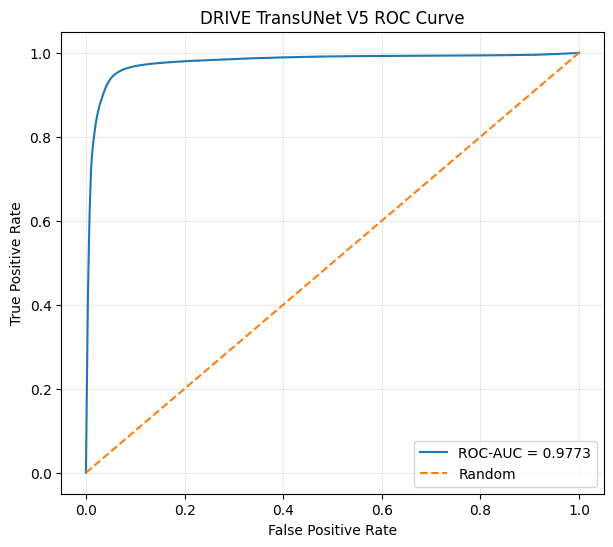

In [11]:
fpr, tpr, _ = roc_curve(val_targets, val_probs)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0,1],[0,1],"--",label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("DRIVE TransUNet V5 ROC Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 12. Precision–Recall curve — PR area under curve

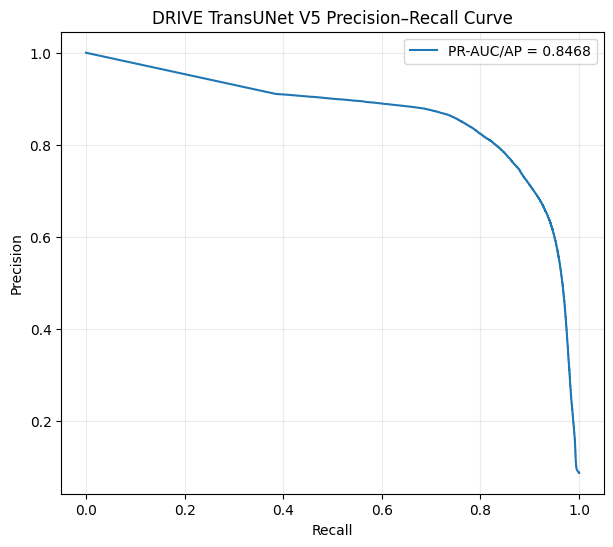

In [12]:
pr_precision, pr_recall, _ = precision_recall_curve(val_targets, val_probs)

plt.figure(figsize=(7,6))
plt.plot(pr_recall, pr_precision, label=f"PR-AUC/AP = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("DRIVE TransUNet V5 Precision–Recall Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 13. Confusion matrix

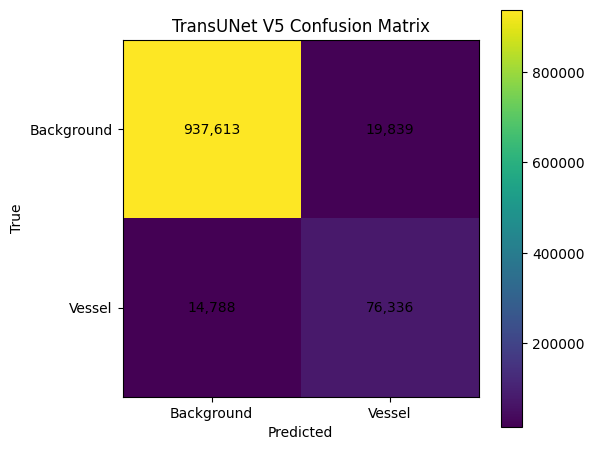

In [13]:
val_pred = (val_probs >= best_threshold).astype(np.uint8)
cm = confusion_matrix(val_targets.astype(np.uint8), val_pred)

plt.figure(figsize=(6,5))
plt.imshow(cm)
plt.title("TransUNet V5 Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks([0,1],["Background","Vessel"])
plt.yticks([0,1],["Background","Vessel"])

for i in range(2):
    for j in range(2):
        plt.text(j,i,f"{cm[i,j]:,}",ha="center",va="center")

plt.colorbar()
plt.tight_layout()
plt.show()


## 14. Training curves: loss, validation Dice, learning rate and gradient norm

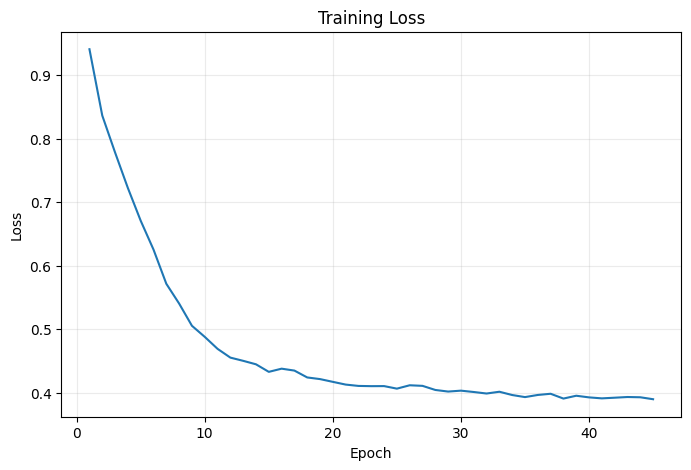

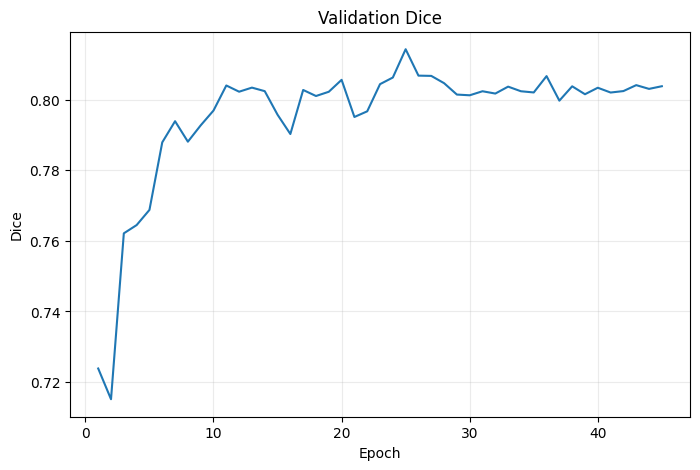

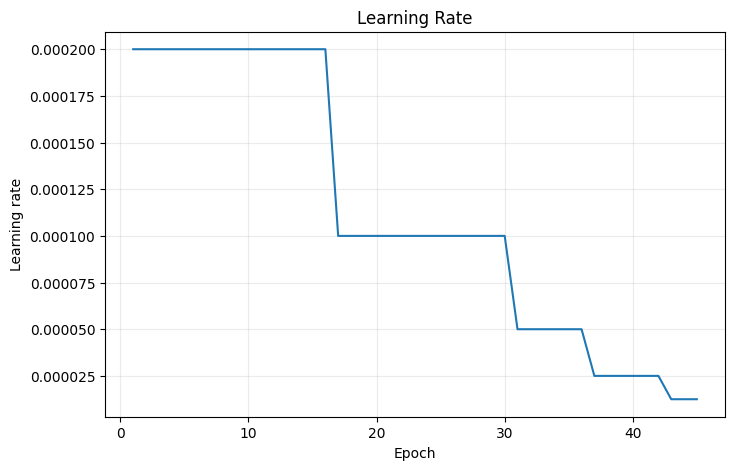

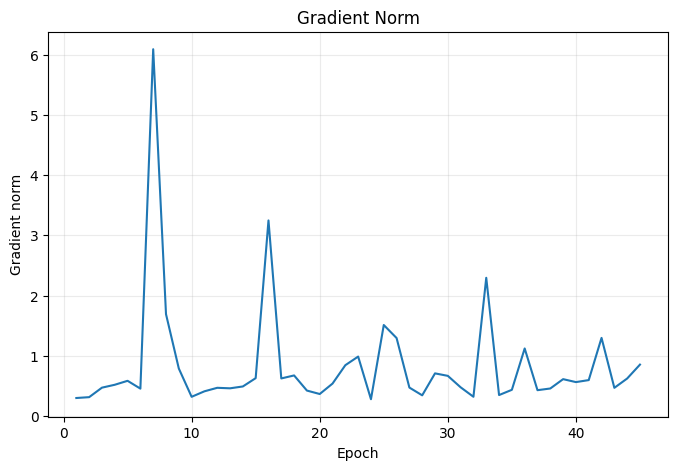

In [14]:
hist = pd.DataFrame(history)

for column, ylabel, title in [
    ("train_loss","Loss","Training Loss"),
    ("val_dice","Dice","Validation Dice"),
    ("lr","Learning rate","Learning Rate"),
    ("grad_norm","Gradient norm","Gradient Norm")
]:
    plt.figure(figsize=(8,5))
    plt.plot(hist["epoch"], hist[column])
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.show()


## 15. Threshold-vs-Dice curve

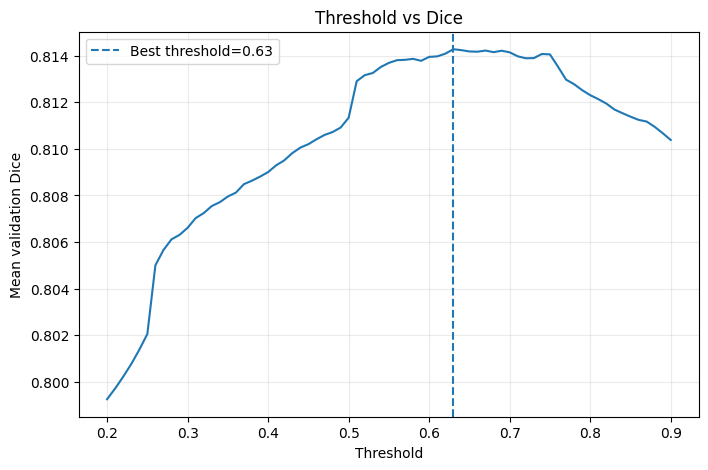

In [15]:
thresholds = np.arange(0.20,0.901,0.01)
threshold_scores = []

for t in thresholds:
    scores = [
        binary_metrics(p.reshape(-1),gt.reshape(-1),float(t))[0]
        for p,gt in val_items
    ]
    threshold_scores.append(np.mean(scores))

plt.figure(figsize=(8,5))
plt.plot(thresholds, threshold_scores)
plt.axvline(best_threshold, linestyle="--", label=f"Best threshold={best_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Mean validation Dice")
plt.title("Threshold vs Dice")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 16. Visual metric comparison

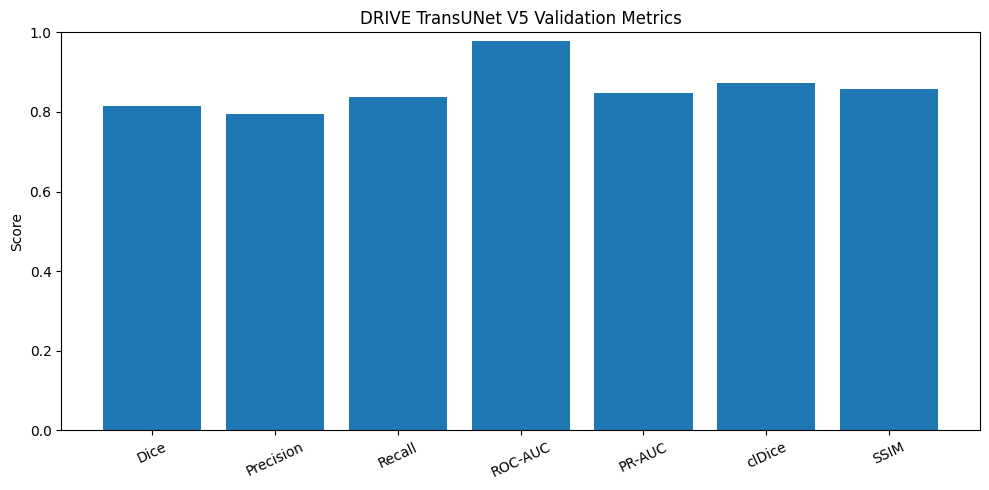

In [16]:
metric_names = ["Dice","Precision","Recall","ROC-AUC","PR-AUC","clDice","SSIM"]
metric_values = [
    np.mean(per_dice), precision, recall, roc_auc,
    pr_auc, np.nanmean(per_cldice), np.mean(per_ssim)
]

plt.figure(figsize=(10,5))
plt.bar(metric_names, metric_values)
plt.ylim(0,1)
plt.ylabel("Score")
plt.title("DRIVE TransUNet V5 Validation Metrics")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


## 17. Separate TransUNet prediction visuals

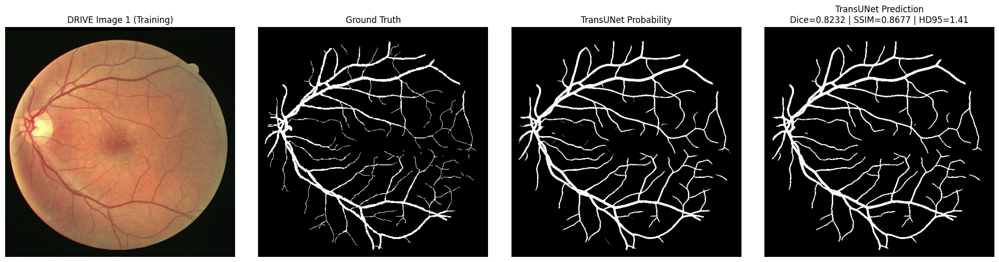

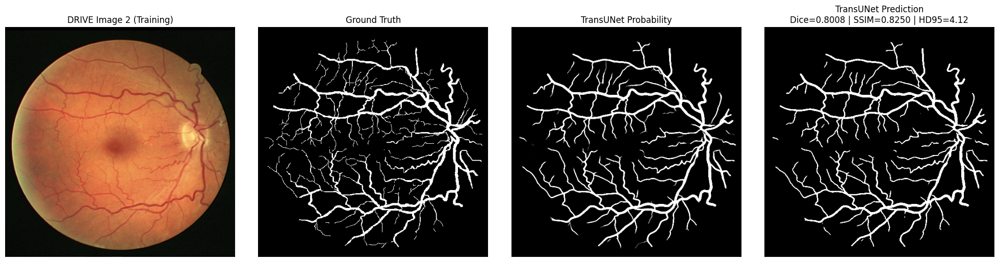

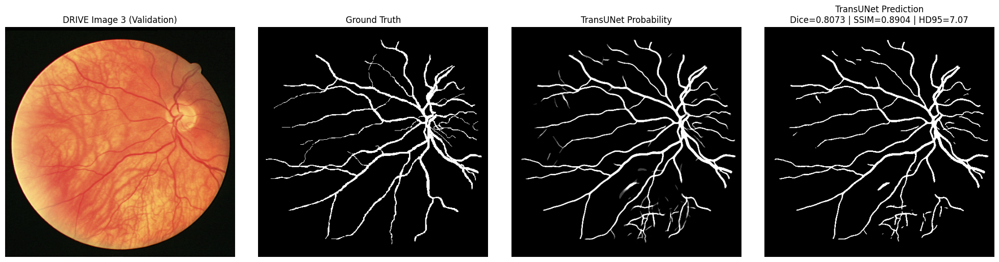

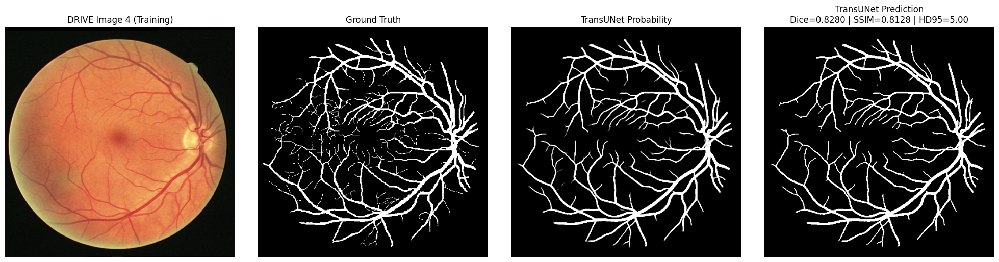

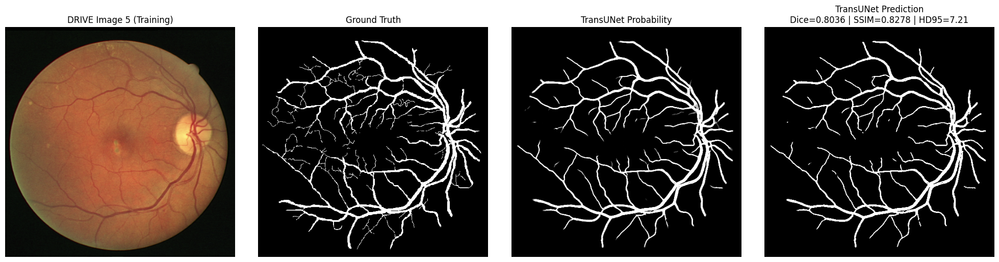

...

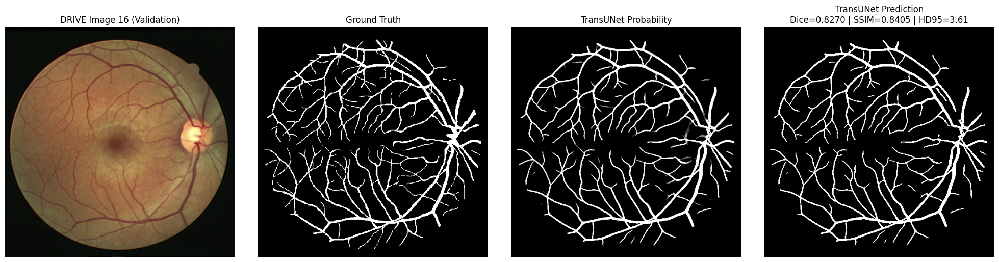

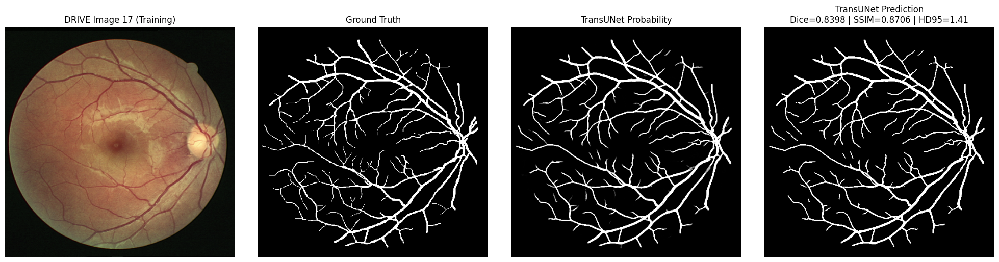

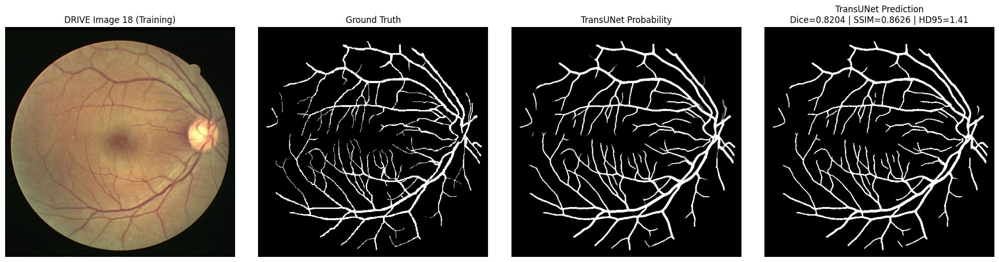

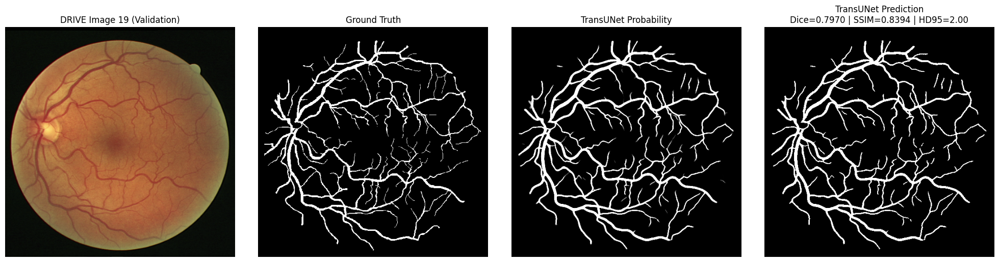

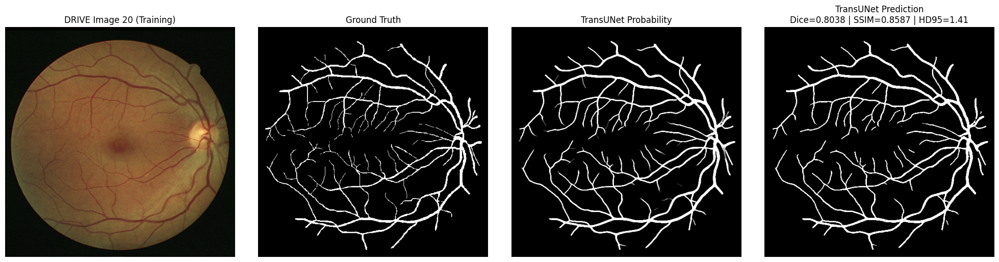

In [17]:
@torch.no_grad()
def show_all_transunet_predictions():
    model.eval()

    for i, (x, y) in enumerate(full_clean):   # ALL 20 images
        p = predict_tta(
            model,
            x.unsqueeze(0).to(device)
        )[0, 0].cpu().numpy()

        gt = y[0].numpy()
        pred = (p >= best_threshold).astype(np.uint8)

        d = binary_metrics(
            p.reshape(-1),
            gt.reshape(-1),
            best_threshold
        )[0]

        s = ssim_np(pred, gt)
        h = hd95_np(pred, gt)

        img = np.clip(
            x.permute(1, 2, 0).numpy() * 0.5 + 0.5,
            0, 1
        )

        # Tell whether this image was used for training or validation
        split_name = "Validation" if i in val_idx else "Training"

        fig, ax = plt.subplots(1, 4, figsize=(20, 5))

        ax[0].imshow(img)
        ax[0].set_title(
            f"DRIVE Image {i+1} ({split_name})"
        )

        ax[1].imshow(gt, cmap="gray")
        ax[1].set_title("Ground Truth")

        ax[2].imshow(p, cmap="gray", vmin=0, vmax=1)
        ax[2].set_title("TransUNet Probability")

        ax[3].imshow(pred, cmap="gray")
        ax[3].set_title(
            f"TransUNet Prediction\n"
            f"Dice={d:.4f} | SSIM={s:.4f} | HD95={h:.2f}"
        )

        for a in ax:
            a.axis("off")

        plt.tight_layout()
        plt.show()


show_all_transunet_predictions()

## 18. Parameter count and architecture check


In [18]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters: {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')
print('Architecture: CNN + parallel Transformer/GNN + gated fusion + attention decoder')


Total parameters: 23,151,659
Trainable parameters: 23,151,659
Architecture: CNN + parallel Transformer/GNN + gated fusion + attention decoder


## 19. Download V6 checkpoint, threshold and history


In [ ]:
from google.colab import files

for path in [TRANS_CHECKPOINT, TRANS_THRESHOLD_FILE, TRANS_HISTORY_FILE]:
    if os.path.exists(path):
        files.download(path)


## Notes

- Uses the same fixed 16/4 DRIVE split as the supplied notebook.
- No pretrained model is required.
- The GNN is no longer a separate post-processing model.
- Dice improvement is **not guaranteed**; compare V6 against the same validation split and threshold-search procedure used for V5.
- If GPU memory is tight, reduce `BATCH_SIZE` before reducing image/patch resolution.
